# Notebook 02 — Machine Selling-Price Prediction

Train and compare regression models to estimate `final_selling_price` from machine specifications.

**Data notice:** this notebook uses synthetic demonstration data only. Its metrics are software-workflow checks, not evidence of actual L&L Machinery pricing accuracy. We exclude IDs and price/cost fields that would not be known when making a new estimate.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Usable quotation records: 400


,quote_id,machine_type,model_series,swing_over_bed_mm,distance_between_centers_mm,spindle_bore_mm,spindle_motor_kw,chuck_size_inch,turret_stations,live_tooling,bar_feeder,chip_conveyor,tailstock_type,controller,data_source,final_selling_price
0,SIMQ-00001,Conventional,SIM-CV-2,420,3000,52,22.0,15.0,0,0,0,0,hydraulic,NONE,SIMULATED,1899.1
1,SIMQ-00002,CNC,SIM-CNC-A,500,750,80,11.0,15.0,10,0,0,1,programmable,CTRL-A,SIMULATED,2296.9
2,SIMQ-00003,Conventional,SIM-CV-2,600,1000,80,22.0,15.0,0,0,0,1,programmable,NONE,SIMULATED,1571.0
3,SIMQ-00004,Conventional,SIM-CV-2,420,1500,80,7.5,8.0,0,0,0,0,hydraulic,NONE,SIMULATED,1314.1
4,SIMQ-00005,CNC,SIM-CNC-C,360,2000,66,7.5,10.0,12,1,0,1,programmable,CTRL-A,SIMULATED,2383.2


Numeric features: ['swing_over_bed_mm', 'distance_between_centers_mm', 'spindle_bore_mm', 'spindle_motor_kw', 'chuck_size_inch', 'turret_stations', 'live_tooling', 'bar_feeder', 'chip_conveyor']
Categorical features: ['machine_type', 'model_series', 'tailstock_type', 'controller']


,Model,MAE,RMSE,R2
0,Random Forest,422.330211,1251.574814,0.305180
1,Extra Trees,434.202958,1389.959745,0.143035


Selected by lowest test MAE: Random Forest


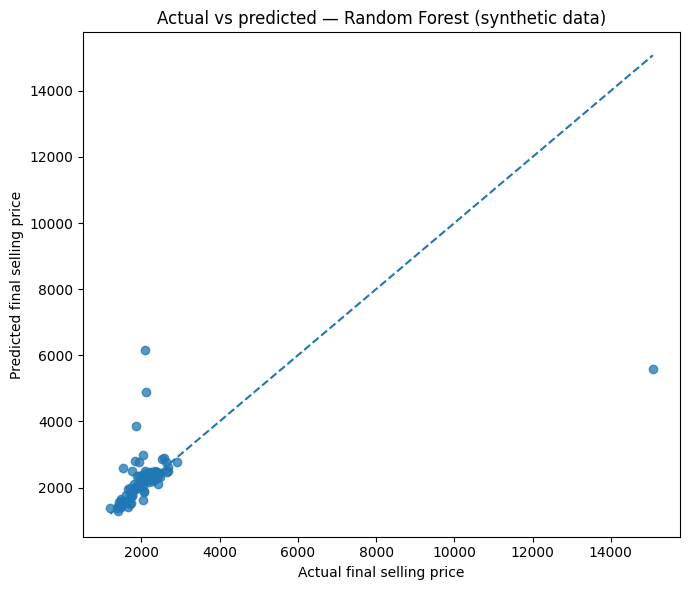

Saved model: /content/drive/MyDrive/LL_MACHINERY_AI_PROJECT/03_Models/price_prediction_model.joblib
Saved evaluation metrics: /content/drive/MyDrive/LL_MACHINERY_AI_PROJECT/04_Evaluation/price_model_metrics.csv
Reminder: retrain and validate with authorized company data before operational use.


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Locate the project in Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    candidates = [
        Path('/content/drive/MyDrive/LL_MACHINERY_AI_PROJECT'),
        Path('/content/drive/MyDrive/LL_MACHINERY_AI_PROJECT')
    ]
    PROJECT_ROOT = next((p for p in candidates if p.is_dir()), candidates[0])
except ImportError:
    PROJECT_ROOT = Path.cwd().parent

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f'Project folder not found: {PROJECT_ROOT}')

DATA_DIR = PROJECT_ROOT / '01_Data' / 'simulated'
MODEL_DIR = PROJECT_ROOT / '03_Models'
REPORT_DIR = PROJECT_ROOT / '04_Evaluation'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Load synthetic data
specs = pd.read_csv(DATA_DIR / 'SIMULATED_machine_specifications.csv')
prices = pd.read_csv(DATA_DIR / 'SIMULATED_historical_prices.csv')

# Remove duplicate quote_id records to ensure 1:1 validation passes
specs = specs.drop_duplicates(subset=['quote_id'])
prices = prices.drop_duplicates(subset=['quote_id'])

# Link specifications to final selling price
data = specs.merge(
    prices[['quote_id', 'final_selling_price']],
    on='quote_id', how='inner', validate='one_to_one'
).dropna(subset=['final_selling_price']).copy()

print('Usable quotation records:', len(data))
display(data.head())

# Use machine specifications available at estimate time.
# Exclude quote_id, provenance label, and target.
target = 'final_selling_price'
X = data.drop(columns=['quote_id', 'data_source', target])
y = data[target]

numeric_features = X.select_dtypes(include=['number', 'bool']).columns.tolist()
categorical_features = X.select_dtypes(exclude=['number', 'bool']).columns.tolist()
print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipe, numeric_features),
    ('categorical', categorical_pipe, categorical_features)
])

# Compare two tree-based regression baselines
candidates = {
    'Random Forest': RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    'Extra Trees': ExtraTreesRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1
    )
}

results = []
trained_models = {}
for name, estimator in candidates.items():
    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('regressor', estimator)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2': r2_score(y_test, predictions)
    })
    trained_models[name] = pipeline

metrics = pd.DataFrame(results).sort_values('MAE').reset_index(drop=True)
display(metrics)
best_name = metrics.loc[0, 'Model']
best_model = trained_models[best_name]
print('Selected by lowest test MAE:', best_name)

# Plot actual versus predicted values
predictions = best_model.predict(X_test)
plt.figure(figsize=(7, 6))
plt.scatter(y_test, predictions, alpha=0.75)
low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], linestyle='--')
plt.xlabel('Actual final selling price')
plt.ylabel('Predicted final selling price')
plt.title(f'Actual vs predicted — {best_name} (synthetic data)')
plt.tight_layout()
plt.show()

# Save the complete preprocessing + model pipeline for the dashboard
model_path = MODEL_DIR / 'price_prediction_model.joblib'
joblib.dump({
    'model': best_model,
    'feature_columns': X.columns.tolist(),
    'target': target,
    'data_source': 'SIMULATED'
}, model_path)
metrics_path = REPORT_DIR / 'price_model_metrics.csv'
metrics.to_csv(metrics_path, index=False)

print('Saved model:', model_path)
print('Saved evaluation metrics:', metrics_path)
print('Reminder: retrain and validate with authorized company data before operational use.')

## Interpreting the results

- **MAE:** average absolute prediction error, in the target's currency units.
- **RMSE:** penalizes large errors more heavily.
- **R²:** proportion of variation explained; it can be negative on unseen data.
- The synthetic dataset is small. Do not present these scores as real business performance.
- Before using company records, confirm permission, currency, target definition, and which features are available when a quote is prepared.